In [38]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score, recall_score, precision_score

In [10]:
pwd

'/home/kali/Documents/DL_Pracs'

In [11]:
df = pd.read_csv("ext_datasets/creditcard.csv")

In [12]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
df.shape

(284807, 31)

In [14]:
df['Class'].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [15]:
X = df.drop('Class', axis=1)
y = df['Class']


In [16]:
y.value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [17]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled.shape

(284807, 30)

In [18]:
x_train_all, x_test, y_train_all, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [19]:
## normal data set split to train autoencoder on.. we do not want the autoencoder to learn to reconstruct the anomalous transactions too, thats how we identify anomalous tx

X_train = x_train_all[y_train_all == 0]

X_train, X_val = train_test_split(
    X_train,
    train_size=0.2,
    random_state=42
)


In [20]:
## scale them all

scaler2 = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(x_test)

In [21]:
input_dim = X_train_scaled.shape[1]
model = keras.Sequential([
    keras.layers.Input(shape=(input_dim,)),

    keras.layers.Dense(16, activation="relu", name="learn_compressedfeatures"),
    keras.layers.Dense(8, activation="relu", name="bottleneck_compressed_datainfo"),
    keras.layers.Dense(16, activation="relu", name="reconstructed_compressed"),

    keras.layers.Dense(input_dim, activation="linear", name="decoded_reconstructed_output")
])

model.summary()

E0000 00:00:1793511540.605760    5824 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ learn_compressedfeatures        │ (None, 16)             │           496 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bottleneck_compressed_datainfo  │ (None, 8)              │           136 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_compressed        │ (None, 16)             │           144 │
│ (Dense)                         │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoded_reconstructed_output    │ (None, 30)             │           510 │
│ (Dense)                         │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer='adam',
    loss='mse',
)

In [24]:
history = model.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=20,
    batch_size=256,
    validation_data=(X_val_scaled, X_val_scaled),
    shuffle=True
)

Epoch 1/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4966 - val_loss: 0.4924
Epoch 2/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4944 - val_loss: 0.4904
Epoch 3/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4924 - val_loss: 0.4887
Epoch 4/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4908 - val_loss: 0.4873
Epoch 5/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.4895 - val_loss: 0.4861
Epoch 6/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.4882 - val_loss: 0.4849
Epoch 7/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.4870 - val_loss: 0.4839
Epoch 8/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4861 - val_loss: 0.4830
Epoch 9/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.4847 - val_loss: 0.4821
Epoch 10/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.4838 - val_loss: 0.4813
Epoch 11/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.4828 - val_loss: 0.4805
Epoch 12/20
178/178 ━━━━━━━━━━━━━━━━━━━━ 2s

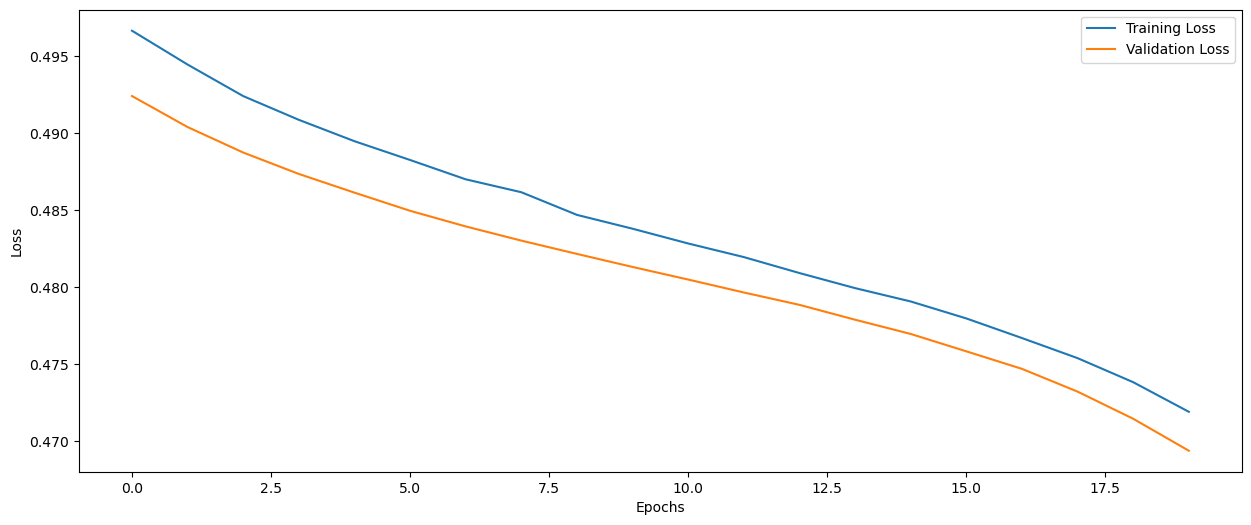

<Axes: >

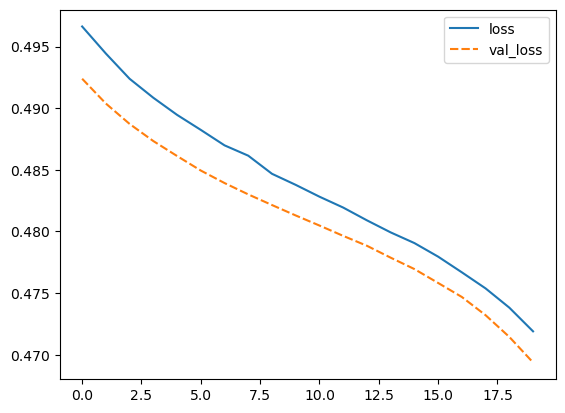

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns
import importlib
importlib.reload(plt)

plt.figure(figsize=(15,6))
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(["Training Loss", "Validation Loss"])
plt.show()

sns.lineplot(history.history)

In [28]:
X_val_reconstructed = model.predict(X_val_scaled)

val_errors = np.mean(
    np.square(X_val_scaled-X_val_reconstructed),
    axis=1
)

print(val_errors[:10])

5687/5687 ━━━━━━━━━━━━━━━━━━━━ 6s 1ms/step
[0.14677429 0.47713279 0.24682598 0.20657505 0.17248383 0.128739
 0.6966682  0.49416378 0.22300473 0.23124811]


In [29]:
## threshold we take as 99th percentile of normal transactions error

threshold= np.percentile(val_errors, 99.3)
print(threshold, np.sum(threshold))

3.9267488199104497 3.9267488199104497


In [30]:
X_test_reconstructed = model.predict(X_test_scaled)
test_error = np.mean(
    np.square(X_test_scaled-X_test_reconstructed),
    axis=1
)

y_pred = (test_error > threshold).astype(int)
np.sum(y_pred)

1781/1781 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


np.int64(490)

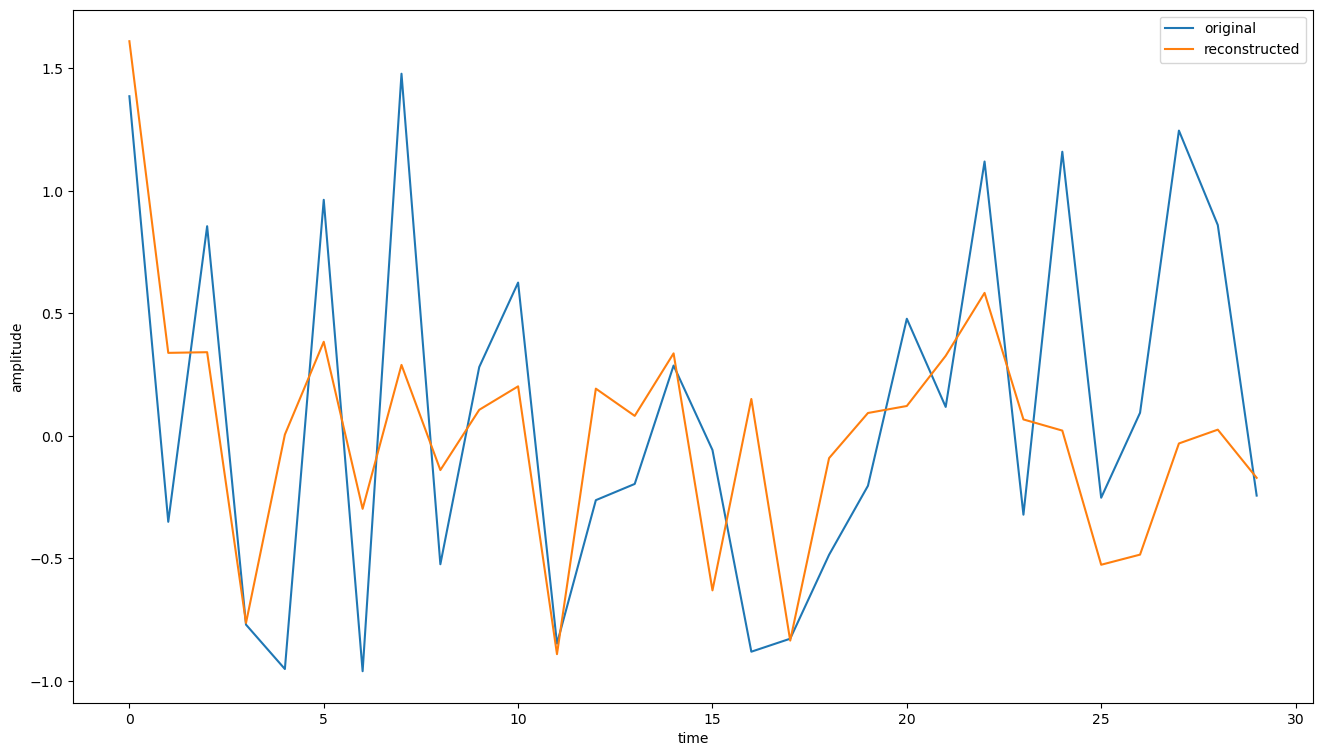

In [36]:
plt.figure(figsize=(16,9))

plt.plot(X_test_scaled[0], label="original")
plt.plot(X_test_reconstructed[0], label="reconstructed")
plt.legend()
plt.xlabel("time")
plt.ylabel("amplitude")
plt.show()

In [39]:
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

Confusion Matrix:
[[56449   415]
 [   23    75]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.99      1.00     56864
           1       0.15      0.77      0.26        98

    accuracy                           0.99     56962
   macro avg       0.58      0.88      0.63     56962
weighted avg       1.00      0.99      0.99     56962

Accuracy: 0.9923106632491837
Precision: 0.15306122448979592
Recall: 0.7653061224489796
F1 Score: 0.25510204081632654


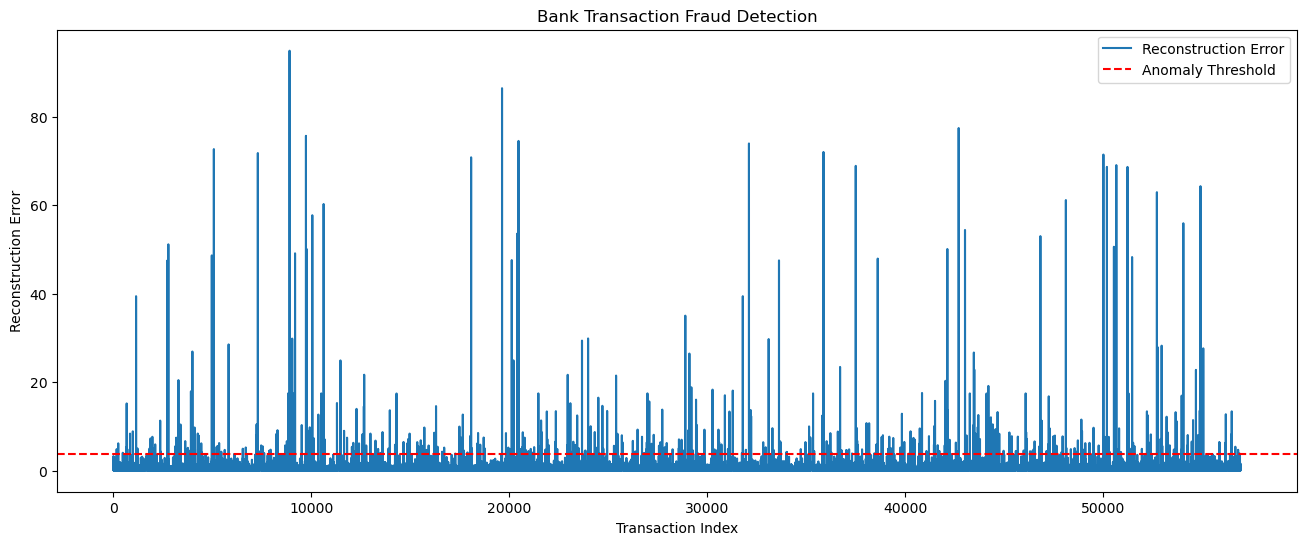

In [40]:
plt.figure(figsize=(16, 6))

plt.plot(test_error, label="Reconstruction Error")

plt.axhline(
    y=threshold,
    color="red",
    linestyle="--",
    label="Anomaly Threshold"
)

plt.xlabel("Transaction Index")
plt.ylabel("Reconstruction Error")
plt.title("Bank Transaction Fraud Detection")
plt.legend()
plt.show()

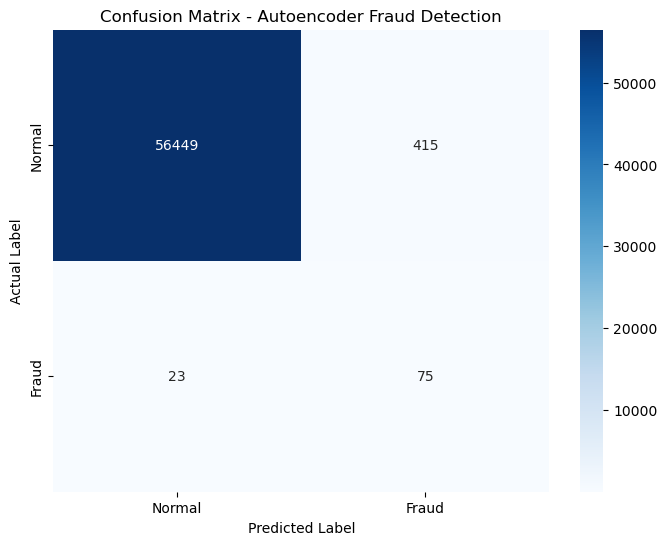

In [41]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Autoencoder Fraud Detection")

plt.show()